In [1]:
import numpy as np
import healpy as hp
import matplotlib.pylab as plt
%matplotlib inline
import rubin_sim.splat as splat
import copy 
from rubin_scheduler.utils import angular_separation
from horseshoe_detailer import HorseshoeAvoidanceDetailer

In [2]:
# use the detailer to load up the stellar catalog we are avoiding
hsd = HorseshoeAvoidanceDetailer()

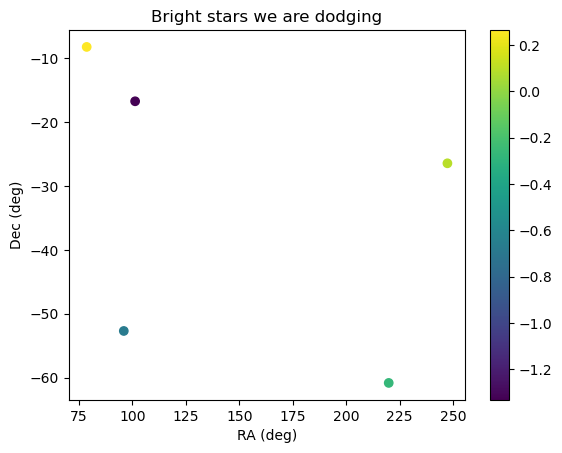

In [3]:
# Let's just pick one of the really bright ones
star_indx = np.where((hsd.star_mags["r"] < 0.5) & (hsd.star_dec_rad < 0))
plt.scatter(np.degrees(hsd.star_ra_rad[star_indx]), np.degrees(hsd.star_dec_rad[star_indx]), c=hsd.star_mags["r"][star_indx])
cb = plt.colorbar()
plt.title("Bright stars we are dodging")
plt.xlabel("RA (deg)")
plt.ylabel("Dec (deg)")
ra = np.degrees(hsd.star_ra_rad[star_indx][0])
dec = np.degrees(hsd.star_dec_rad[star_indx][0])


In [4]:
# Define a report element that we want to run. Needs branch maf-proto of rubin_sim to run
class HighResSpotElement(splat.BaseReportElement):
    def compute_elements(self,visits_df=None, visits_array=None, nside=1024, band="r", ra=0., dec=0., radius=10.):
        sl = splat.Slicer(nside=nside)
        distance = angular_separation(visits_array["fieldRA"], visits_array["fieldDec"], ra, dec)
        info = {"data_source": self.run_name}
        info["observations_subset"] = self.subset + "\nband=%s\nDistance to point=%.2f deg" % (band, radius)

        metrics = []
        infos = []
        plot_dicts = []

        # Coadd depth
        metrics.append(splat.CoaddM5Metric(band))
        temp_info = copy.copy(info)
        temp_info["group"] = "Basics"
        temp_info["subgroup"] = "Coadd"
        infos.append(temp_info)
        plot_dicts.append({})

        # Number of visits
        metrics.append(splat.CountMetric())
        temp_info = copy.copy(info)
        temp_info["group"] = "Basics"
        temp_info["subgroup"] = "Counts"
        infos.append(temp_info)
        plot_dicts.append(
            {"log": True, "min": 1, "norm": "log", "cb_params": {"format": "%i", "n_ticks": 4}}
        )        
        sub_data = visits_array[np.where( (visits_array["band"] == band) & (distance <= radius))[0]]

        hp_arrays, infos = sl(sub_data, metrics, info=infos)

        return hp_arrays, infos, None

In [5]:
horse = HighResSpotElement("horseshoe_radius_0_v5.3.7_10yrs.db")
h0_hp_a, h_infos, _temp = horse(ra=ra, dec=dec)

horse = HighResSpotElement("horseshoe_radius_1_v5.3.7_10yrs.db")
h1_hp_a, h_infos, _temp = horse(ra=ra, dec=dec)

horse = HighResSpotElement("horseshoe_radius_2_v5.3.7_10yrs.db")
h2_hp_a, h_infos, _temp = horse(ra=ra, dec=dec)



In [6]:
base = HighResSpotElement("baseline_v5.3.7_10yrs.db")
b_hp_arrays, b_infos, b_summaries = base(ra=ra, dec=dec)



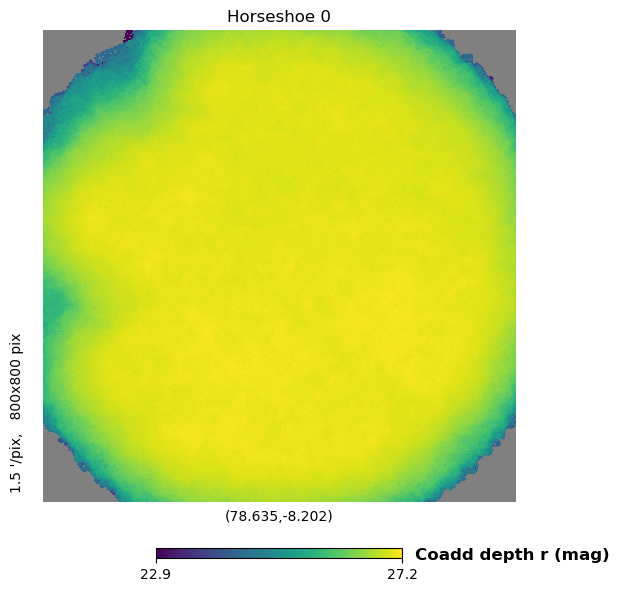

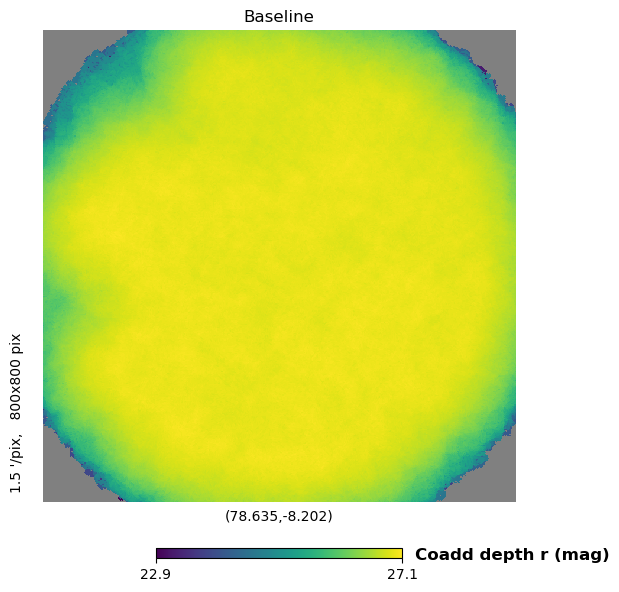

In [7]:
hp.gnomview(h0_hp_a[0], rot=(ra,dec), title="Horseshoe 0", xsize=800, unit="Coadd depth r (mag)")
hp.gnomview(b_hp_arrays[0], rot=(ra,dec), title="Baseline", xsize=800, unit="Coadd depth r (mag)")

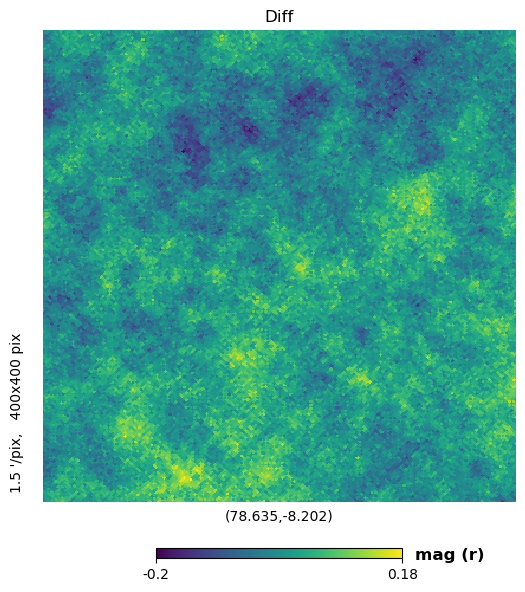

In [8]:
hp.gnomview(h0_hp_a[0] -b_hp_arrays[0] , rot=(ra,dec), title="Diff", unit="mag (r)", xsize=400)

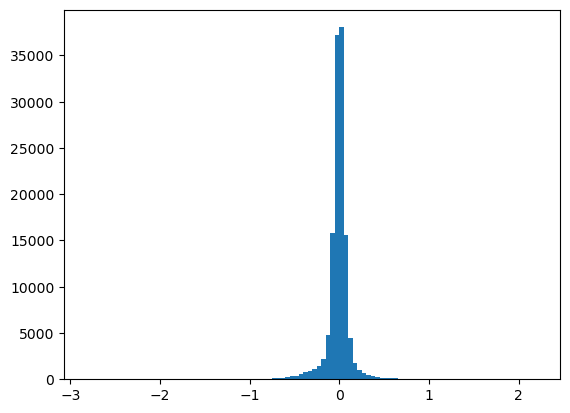

In [9]:
_temp = plt.hist(h0_hp_a[0] -b_hp_arrays[0], bins=100)

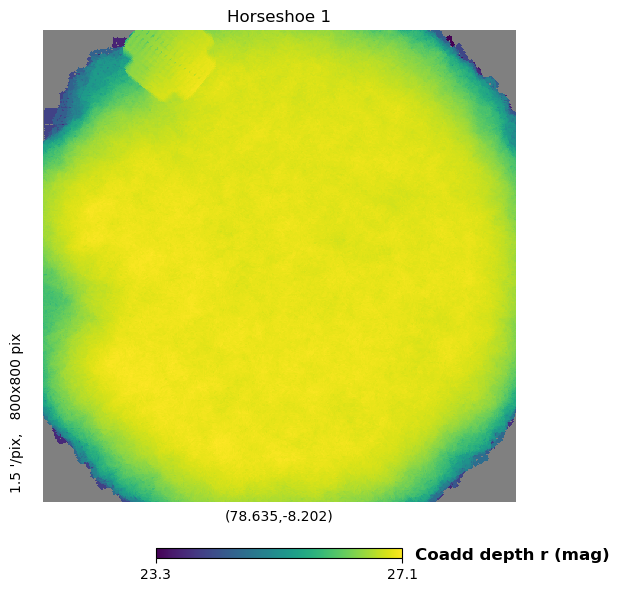

In [10]:
hp.gnomview(h1_hp_a[0], rot=(ra,dec), title="Horseshoe 1", xsize=800, unit="Coadd depth r (mag)")


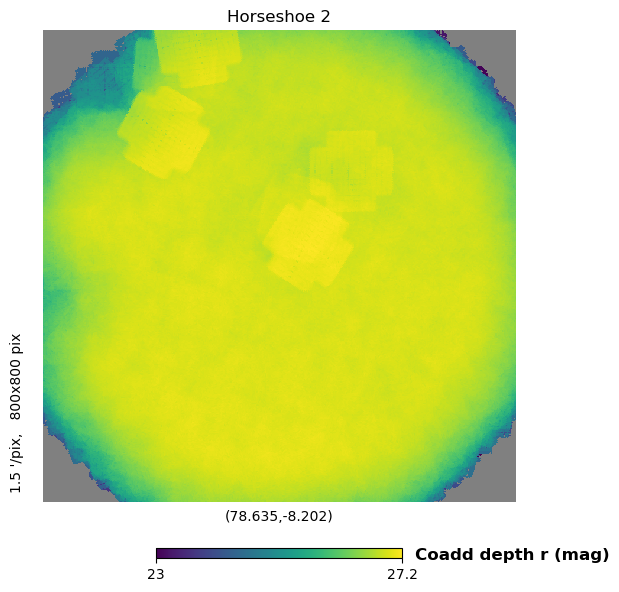

In [11]:
hp.gnomview(h2_hp_a[0], rot=(ra,dec), title="Horseshoe 2", xsize=800, unit="Coadd depth r (mag)")


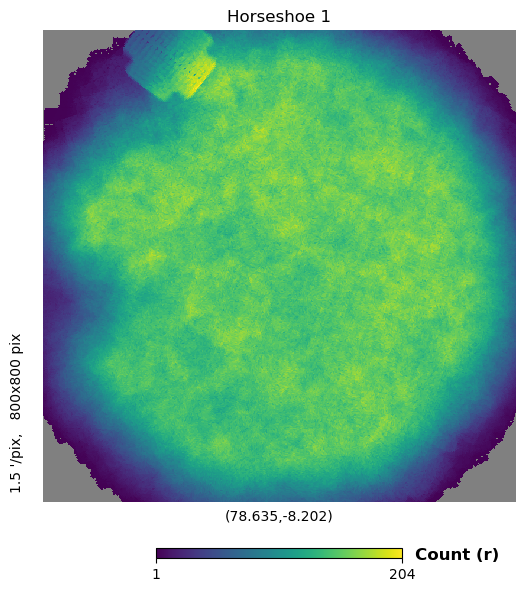

In [12]:

hp.gnomview(h1_hp_a[1], rot=(ra,dec), title="Horseshoe 1", xsize=800, unit="Count (r)")


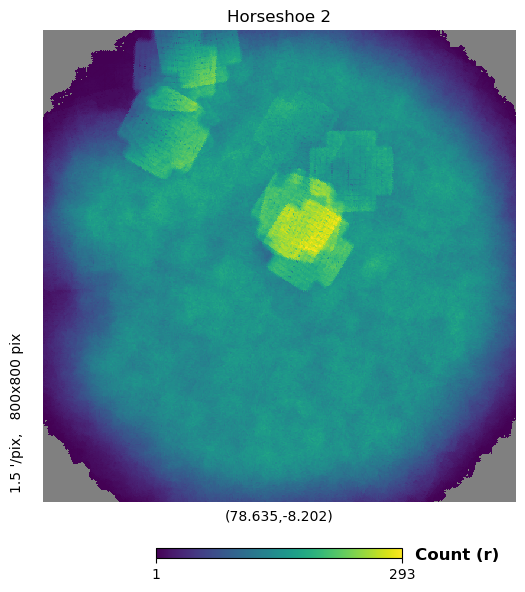

In [13]:
hp.gnomview(h2_hp_a[1], rot=(ra,dec), title="Horseshoe 2", xsize=800, unit="Count (r)")


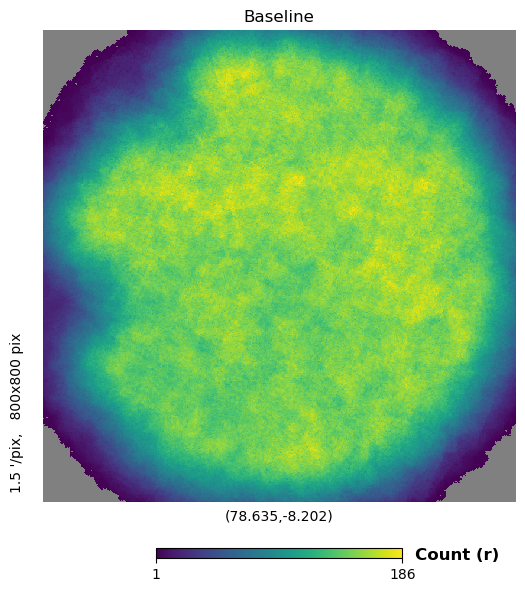

In [14]:
hp.gnomview(b_hp_arrays[1], rot=(ra,dec), title="Baseline", xsize=800, unit="Count (r)")


| run | inner_radius  | outer_radius | offset_deg|
|-----| ------- |   ------- |  --------|
|0   |  1.995  |        2.025  |      0.05 |
|1  |   1.9     |       2.1     |     0.21 |
|2 |    1.7      |      2.2      |    0.51    |      
